In [1]:
""""
Copyright (C) 2025 ETH Zurich, Stefan J.P. Chrin, Gregory Landrum, Sereina Riniker
"""

import sys
sys.path.append("../../../SRC/")

### Define Parameters and preprocess the data

In [2]:
from DDG_ANALYSIS.B_PREPROCESS import preprocess

# --- Dictionary mapping file names to their json file paths ---
files = {
    "RFR 2D": "../../../A_MODELS/2D/STRAT/B_DDG_FROM_DG/ddG_pred_&_error_all_splits.json",
    "RFR 3D": "../../../A_MODELS/3D/STRAT/B_DDG_FROM_DG/ddG_pred_&_error_all_splits.json",
    "Pycomsia": "../../../A_MODELS/PYC/STRAT/C_DDG_FROM_DG/ddG_pred_&_error_all_splits.json",
    "Pycomsia (MIF)": "../../../A_MODELS/MIF/STRAT/C_DDG_FROM_DG/ddG_pred_&_error_all_splits.json",
    "Meta-learner": "../../../A_MODELS/Z_META/DDG/STRAT/ddG_ridge_LOO_pred&error.json",
    "FEP (OFF)": "../../../A_MODELS/FEP/DDG/OFF/OFF_STRAT_ddG_FROM_FEP_GRAPH_pred&error.json",
    "FEP (OPLS3e)": "../../../A_MODELS/FEP/DDG/OPLS/OPLS_STRAT_ddG_FROM_FEP_GRAPH_pred&error.json"
}


DISPLAY_ORDER = ["FEP (OPLS3e)", "FEP (OFF)", "Meta-learner" ,"Pycomsia (MIF)", "Pycomsia", "RFR 3D", "RFR 2D"]
DISPLAY_ORDER.reverse()
ALPHA = 0.01
TARGETS_TO_SKIP = ("galectin","p2","thrombin","cdk8","hif2a","hunt","eg5","jnk1")
METRICS = ["rmse", "kendalls_tau", "window_tau", "slope_diff"]

results_all, bad_splits = preprocess(files, TARGETS_TO_SKIP)


No splits removed.


In [3]:
# Check which splits have constant labels or predictions
print(bad_splits)

{}


### Friedman ANOVA

In [4]:
from DDG_ANALYSIS.C_FRIEDMAN_ANOVA import run_friedman

friedman_results = run_friedman(results_all, METRICS, TARGETS_TO_SKIP=TARGETS_TO_SKIP)
print(friedman_results)

{'rmse': {'bace': {'statistic': 287.0614285714287, 'p_value': 4.834080679619088e-59}, 'cdk2': {'statistic': 327.4200000000001, 'p_value': 1.0816239977754073e-67}, 'cmet': {'statistic': 308.4085714285716, 'p_value': 1.2904021574344927e-63}, 'mcl1': {'statistic': 431.1471428571431, 'p_value': 5.5947110903218295e-90}, 'p38': {'statistic': 193.0971428571429, 'p_value': 5.584003243133936e-39}, 'pde10': {'statistic': 476.2800000000002, 'p_value': 1.079926324641712e-99}, 'pde2': {'statistic': 427.6714285714288, 'p_value': 3.1298363199888777e-89}, 'pfkfb3': {'statistic': 235.54714285714317, 'p_value': 5.01219817807286e-48}, 'ptp1b': {'statistic': 219.25285714285747, 'p_value': 1.5016553728340552e-44}, 'ros1': {'statistic': 139.6157142857146, 'p_value': 1.207959486410198e-27}, 'shp2': {'statistic': 316.4228571428571, 'p_value': 2.469364571254268e-65}, 'syk': {'statistic': 511.5514285714289, 'p_value': 2.729626111489524e-107}, 'tnks2': {'statistic': 261.05999999999995, 'p_value': 1.7724991048675

### Wilcoxon test

In [5]:
from DDG_ANALYSIS.D_WILCOXON import compute_wilcox_posthoc
wilcox_posthoc_results = compute_wilcox_posthoc(results_all, metrics=METRICS, targets_to_skip=TARGETS_TO_SKIP)


### Significance plot

rmse significance by target


/home/schrin/MASTERS_THESIS_STEFAN_CHRIN_PAPER_RERUNZZ_DEPTH_5_FINAL_PAPER/ZZ_MA_FROM_GITLAB/TEST_COPY_FINAL_REPO_AND_COMPARE/ml_vs_fep/B_COMPARE_METHODS/DDG/EFFECT_SIZE_PLOTS/../../../SRC/DDG_ANALYSIS/D_WILCOXON.py:205: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


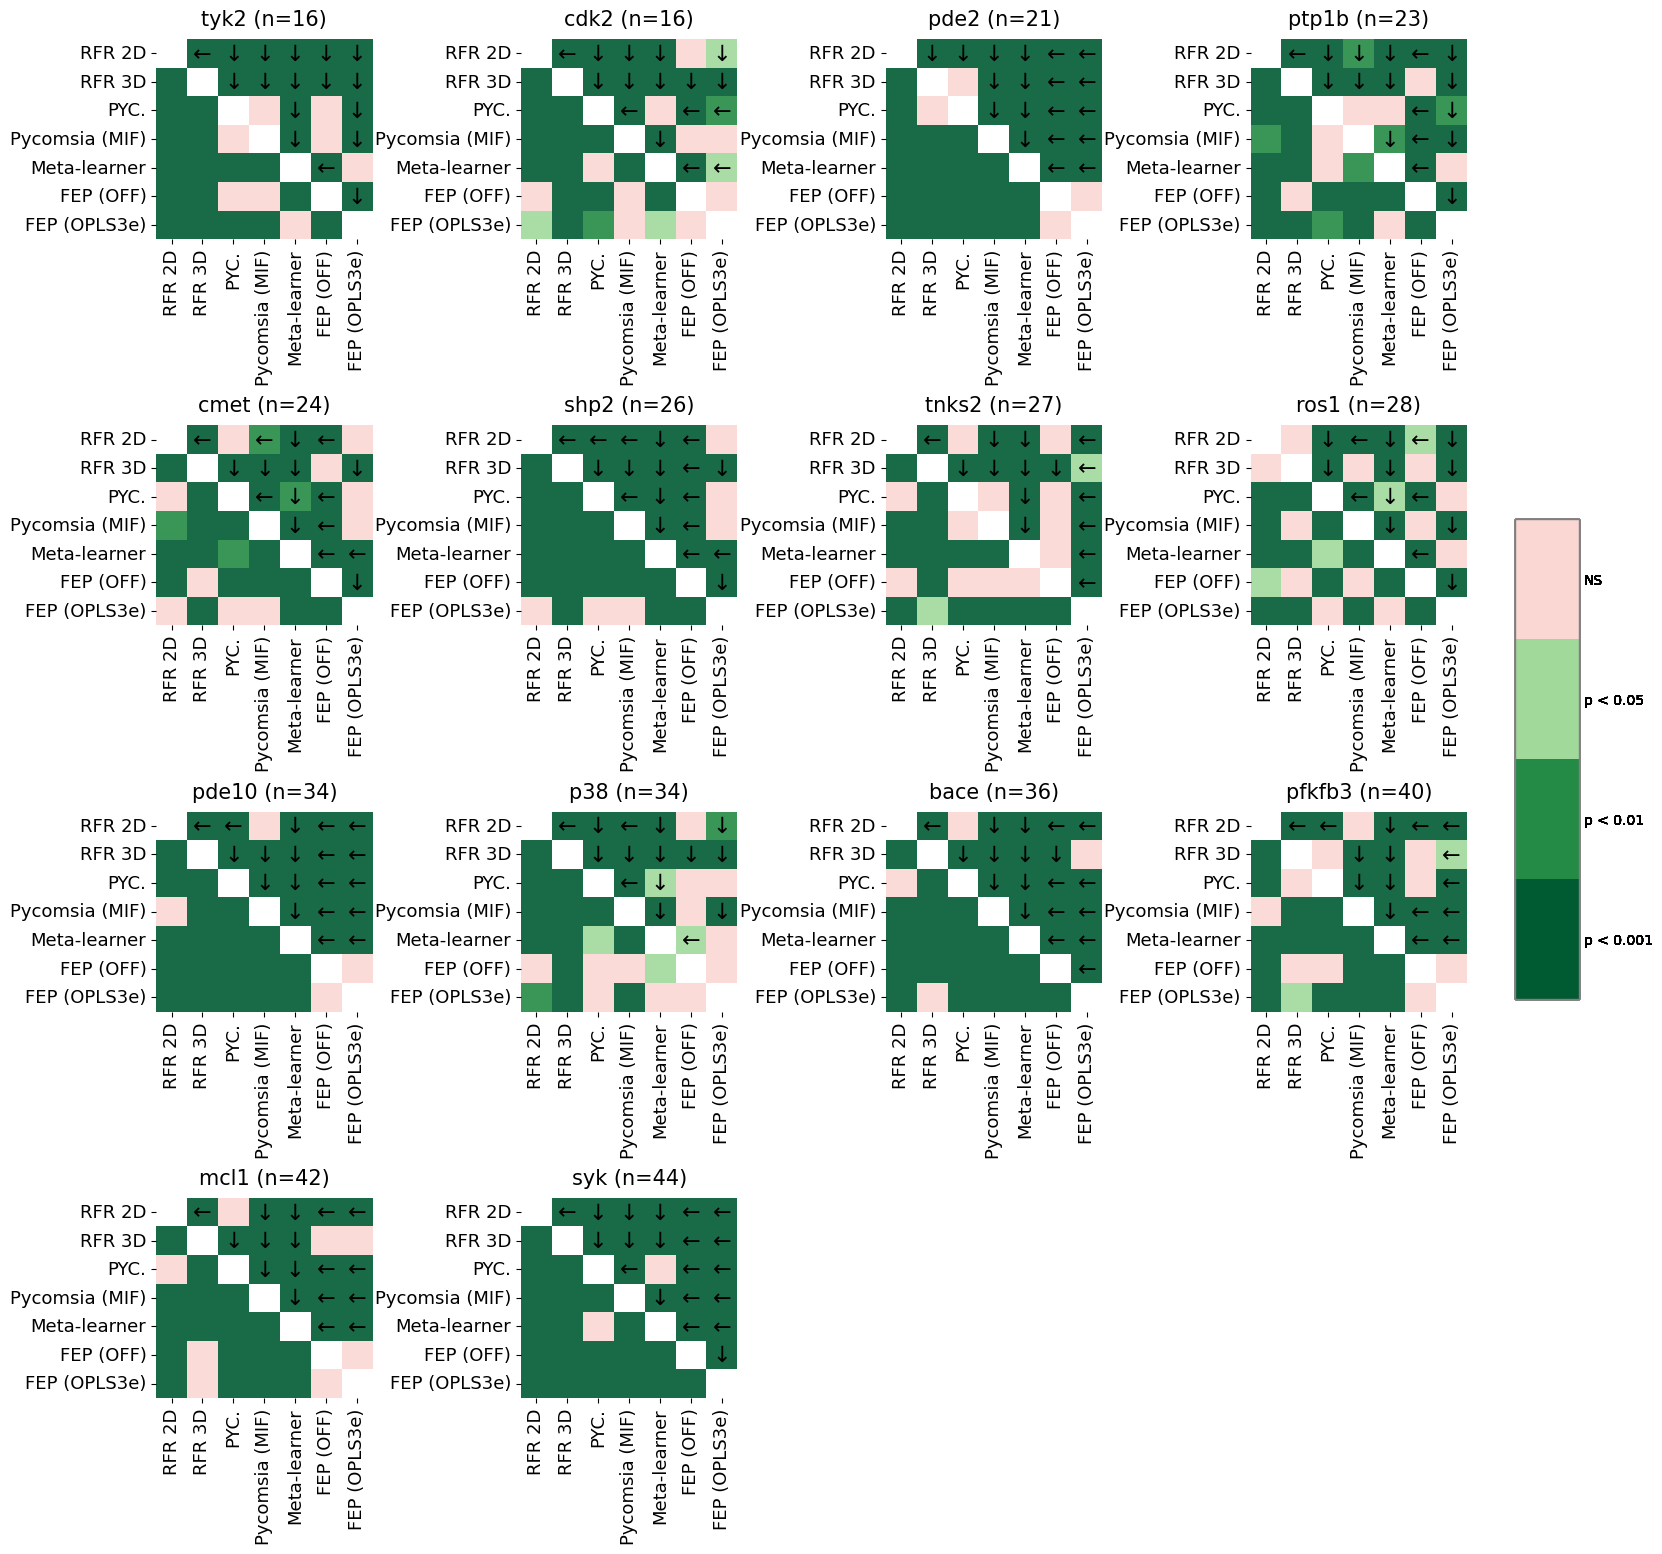

kendalls_tau significance by target


/home/schrin/MASTERS_THESIS_STEFAN_CHRIN_PAPER_RERUNZZ_DEPTH_5_FINAL_PAPER/ZZ_MA_FROM_GITLAB/TEST_COPY_FINAL_REPO_AND_COMPARE/ml_vs_fep/B_COMPARE_METHODS/DDG/EFFECT_SIZE_PLOTS/../../../SRC/DDG_ANALYSIS/D_WILCOXON.py:205: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


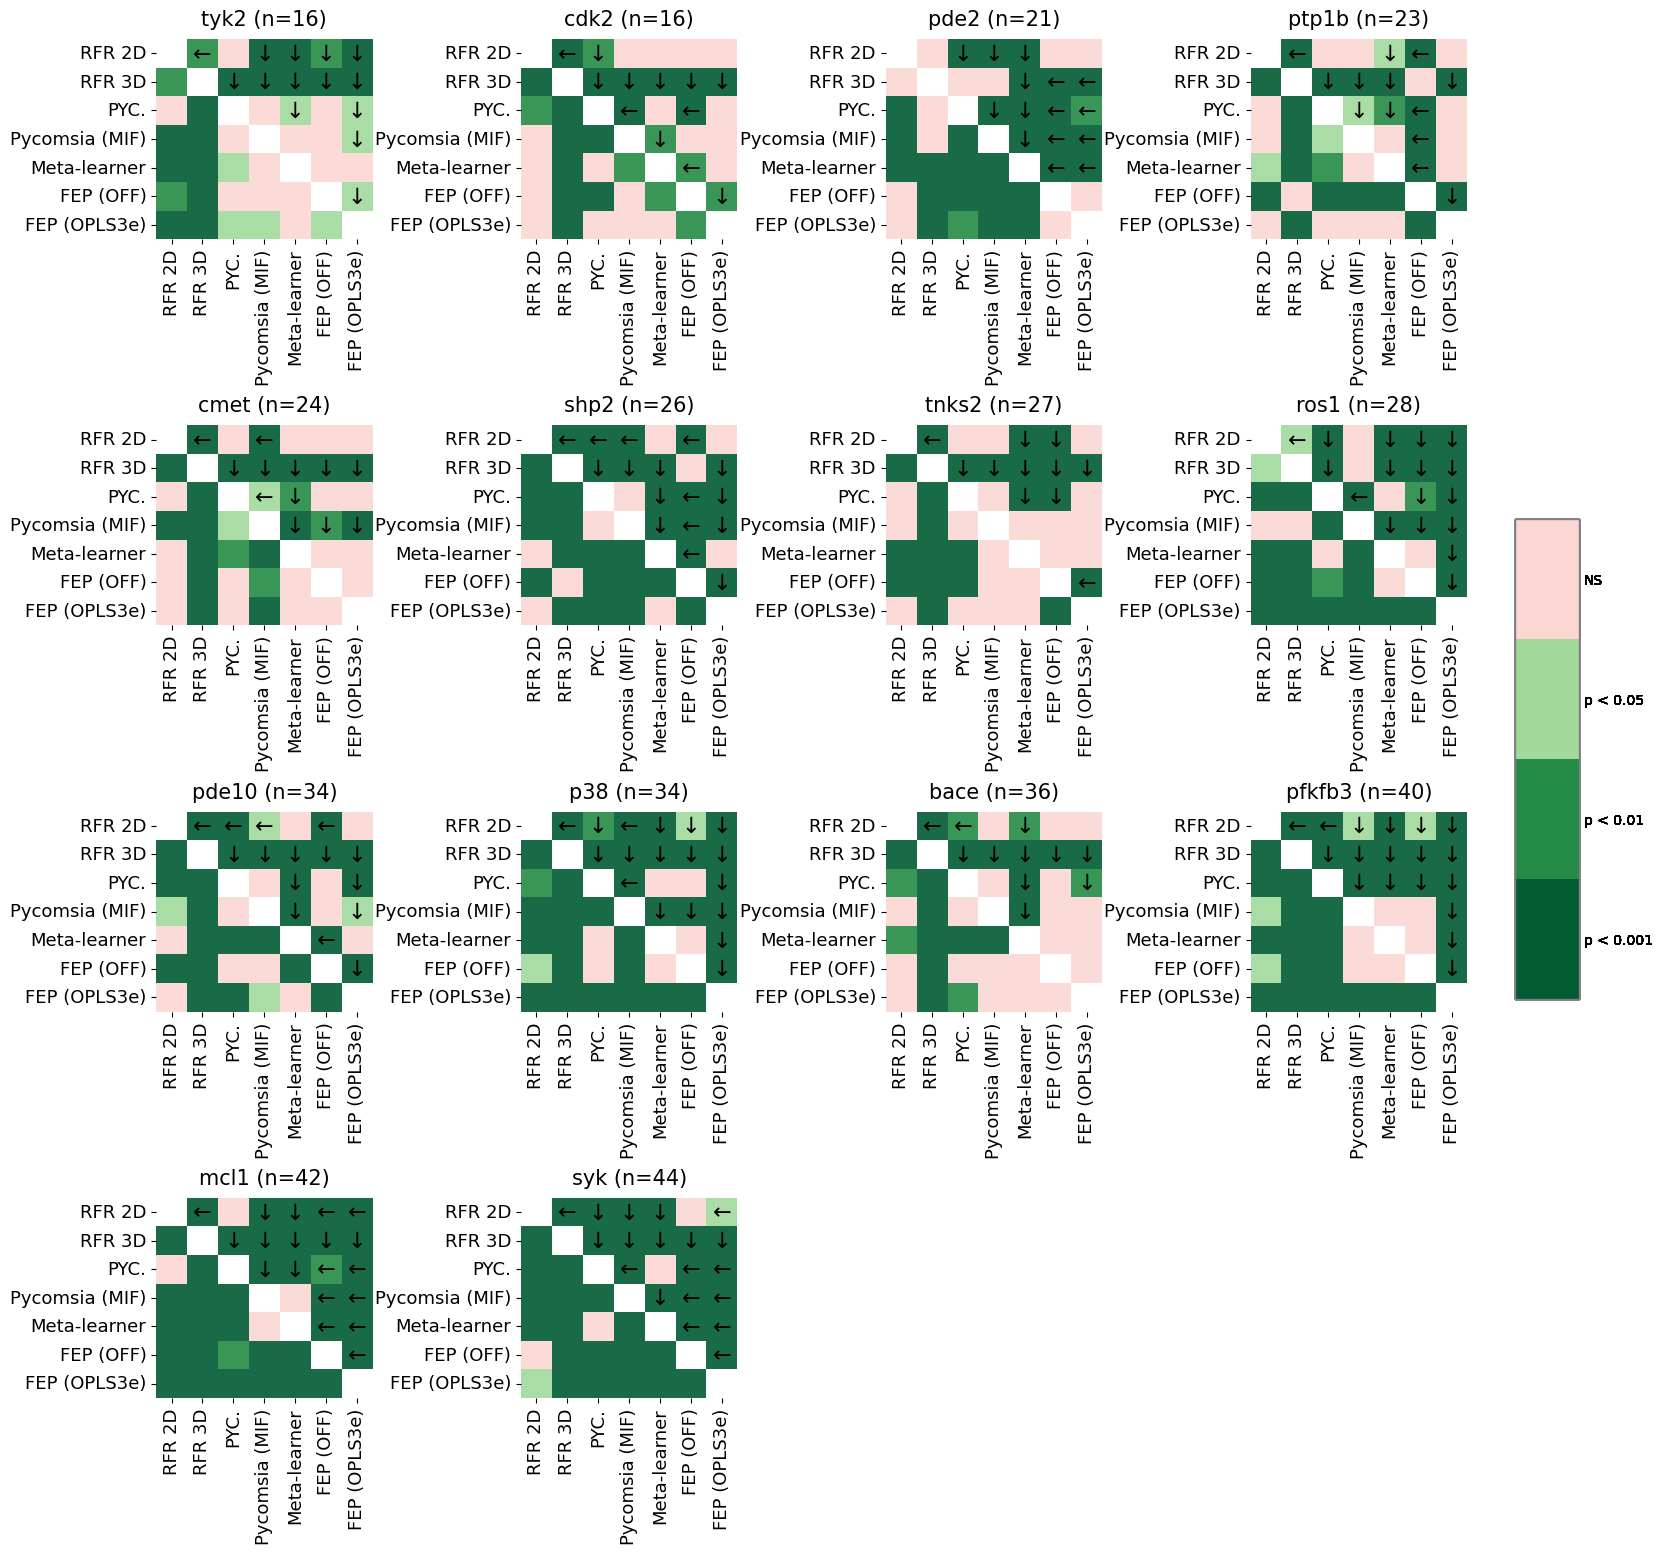

window_tau significance by target


/home/schrin/MASTERS_THESIS_STEFAN_CHRIN_PAPER_RERUNZZ_DEPTH_5_FINAL_PAPER/ZZ_MA_FROM_GITLAB/TEST_COPY_FINAL_REPO_AND_COMPARE/ml_vs_fep/B_COMPARE_METHODS/DDG/EFFECT_SIZE_PLOTS/../../../SRC/DDG_ANALYSIS/D_WILCOXON.py:205: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


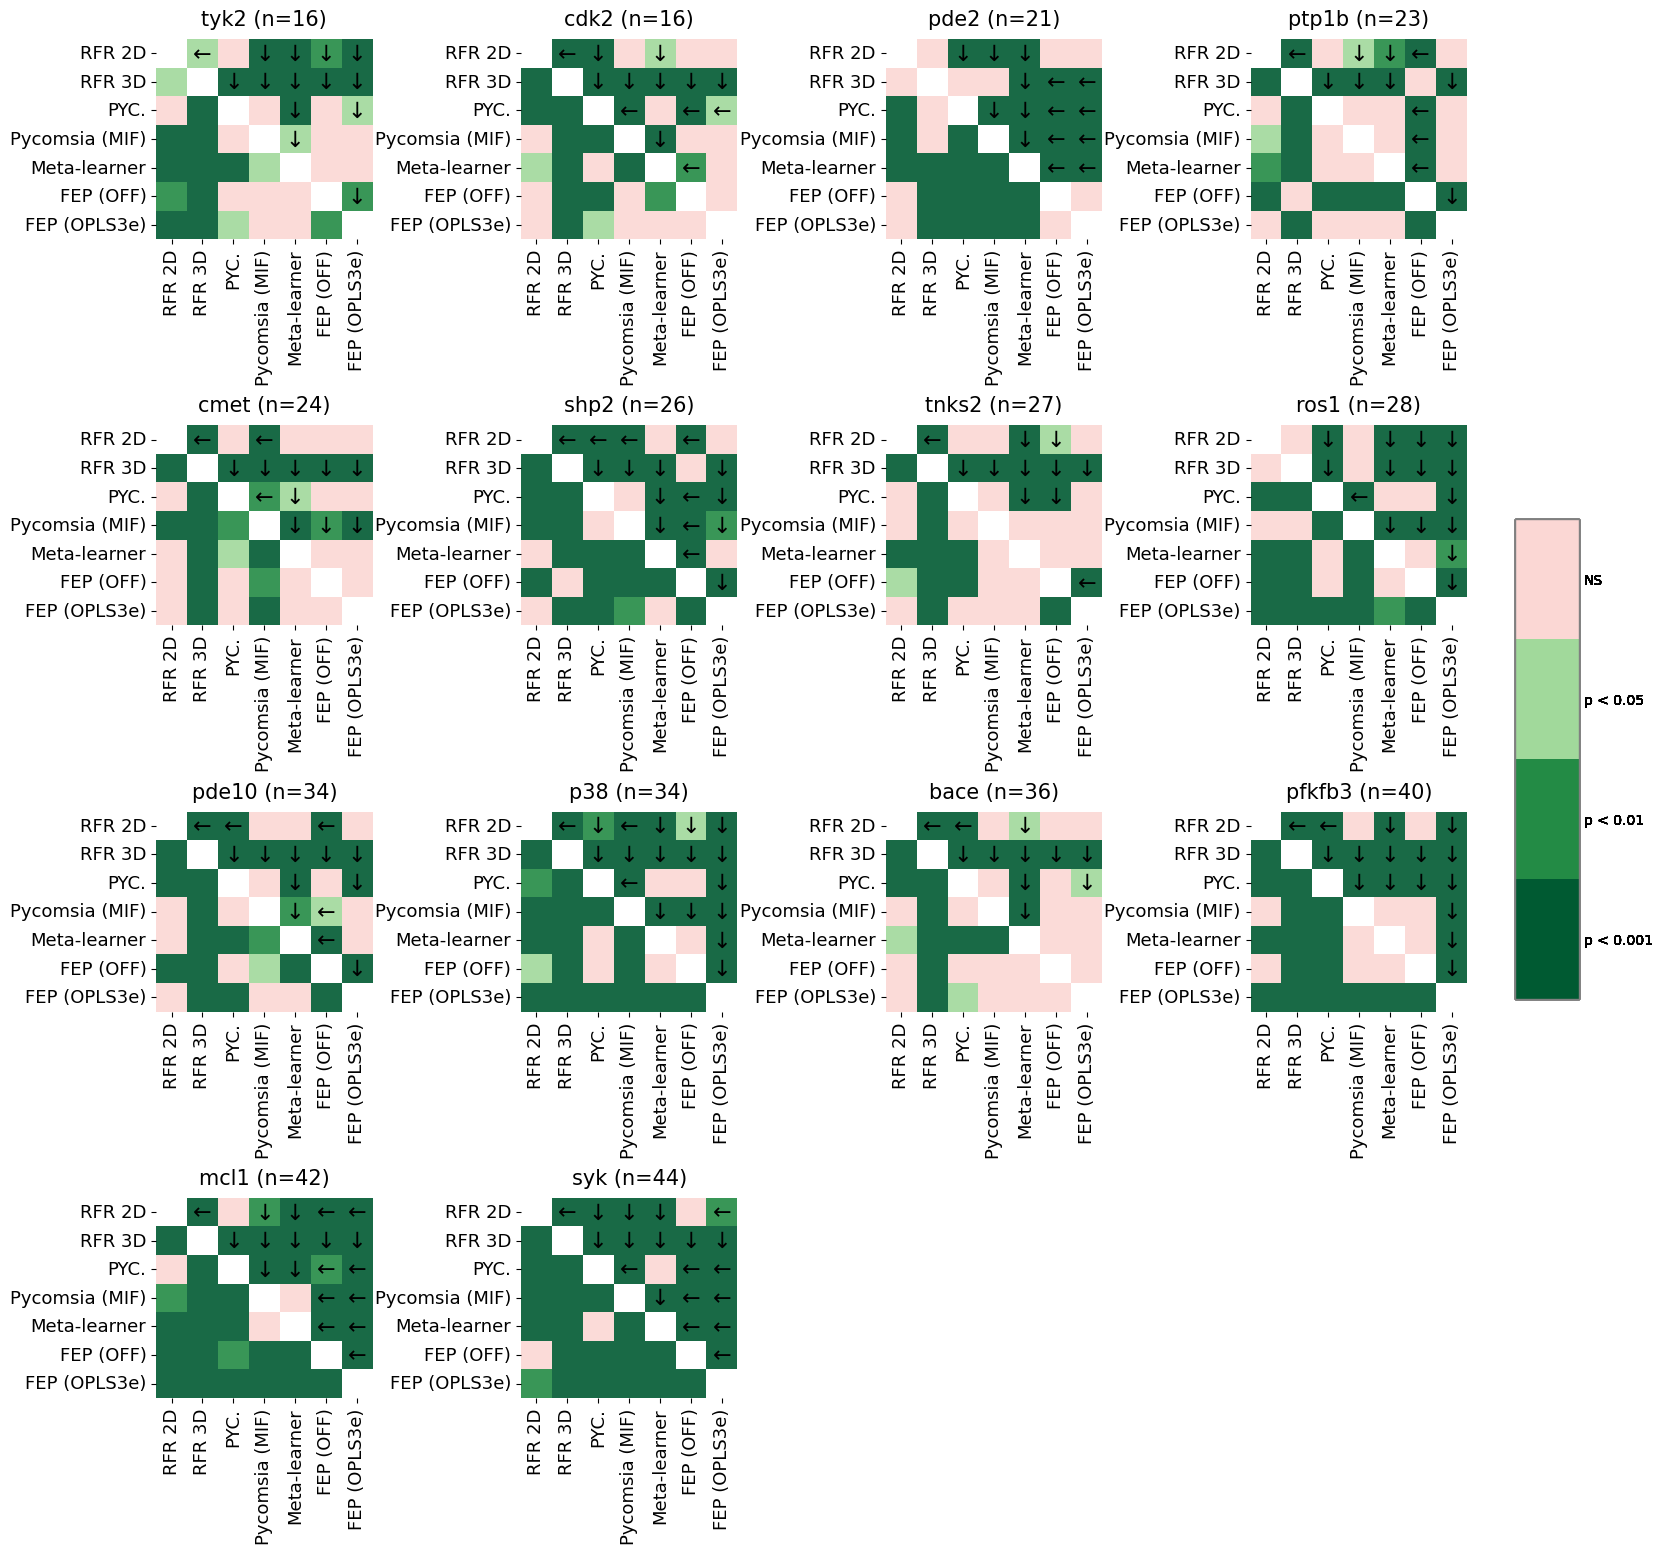

slope_diff significance by target


/home/schrin/MASTERS_THESIS_STEFAN_CHRIN_PAPER_RERUNZZ_DEPTH_5_FINAL_PAPER/ZZ_MA_FROM_GITLAB/TEST_COPY_FINAL_REPO_AND_COMPARE/ml_vs_fep/B_COMPARE_METHODS/DDG/EFFECT_SIZE_PLOTS/../../../SRC/DDG_ANALYSIS/D_WILCOXON.py:205: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


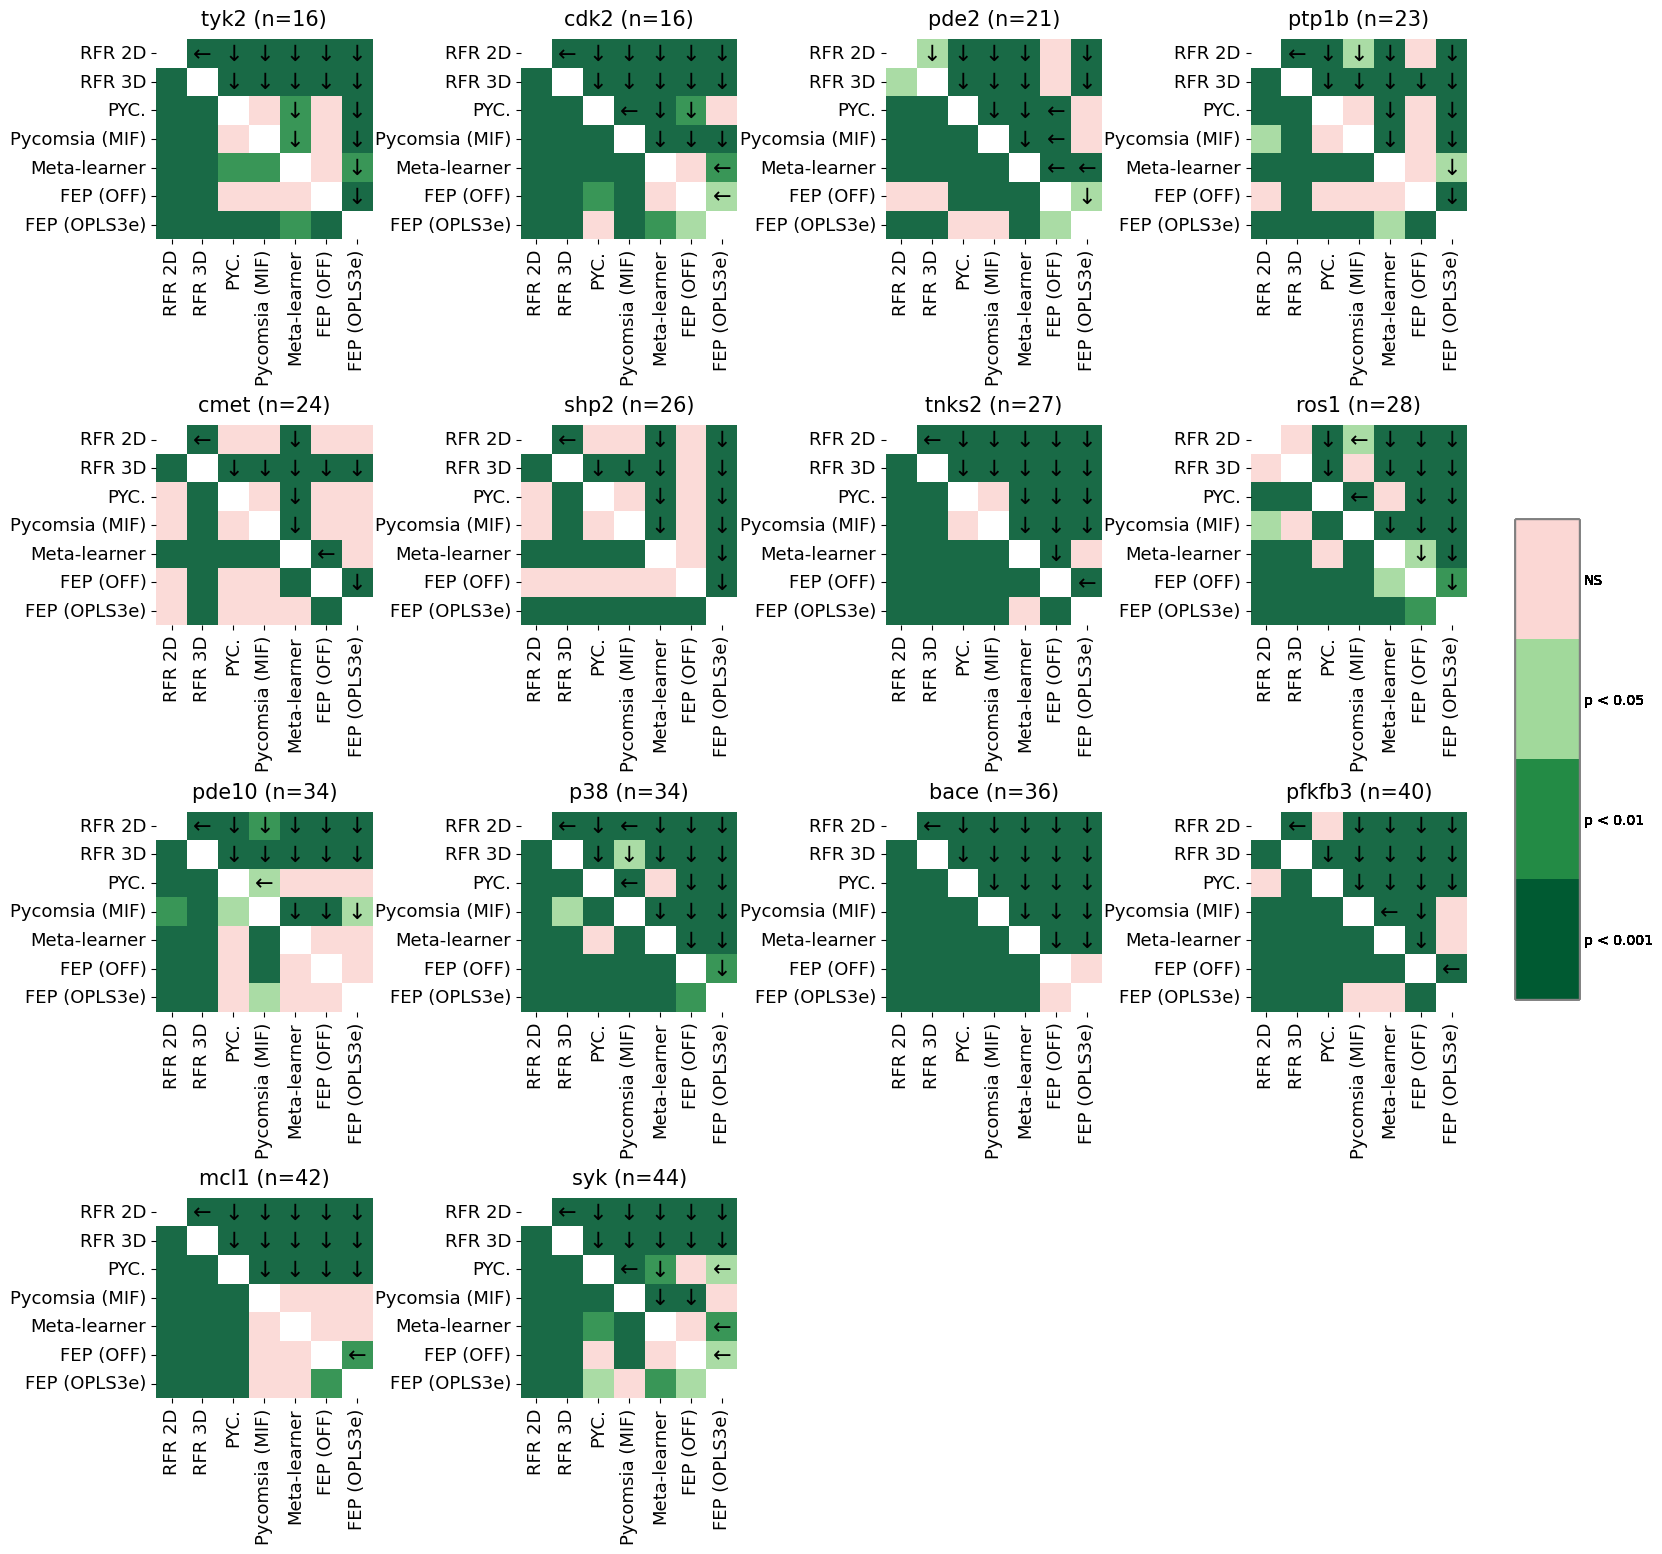

In [6]:
from DDG_ANALYSIS.D_WILCOXON import sign_plot
sign_plot(
    results_all,
    wilcox_posthoc_results,
    DISPLAY_ORDER,
    target_counts_path="../../../0_DATA/N_COMPOUNDS_PER_TARGET.json",
    metrics=METRICS,
    targets_to_skip=TARGETS_TO_SKIP,
    n_cols=4,
    arrow_threshold=0.05, # This is the p value for an arrow to show, should be in accordance with the legend (green -> has an arrow)
    alpha=0.9, # this alpha is how seethrough plot is, not to be mixed up with ALPHA (p value)
)

### Effect size & Significance (Based on wilcoxon)

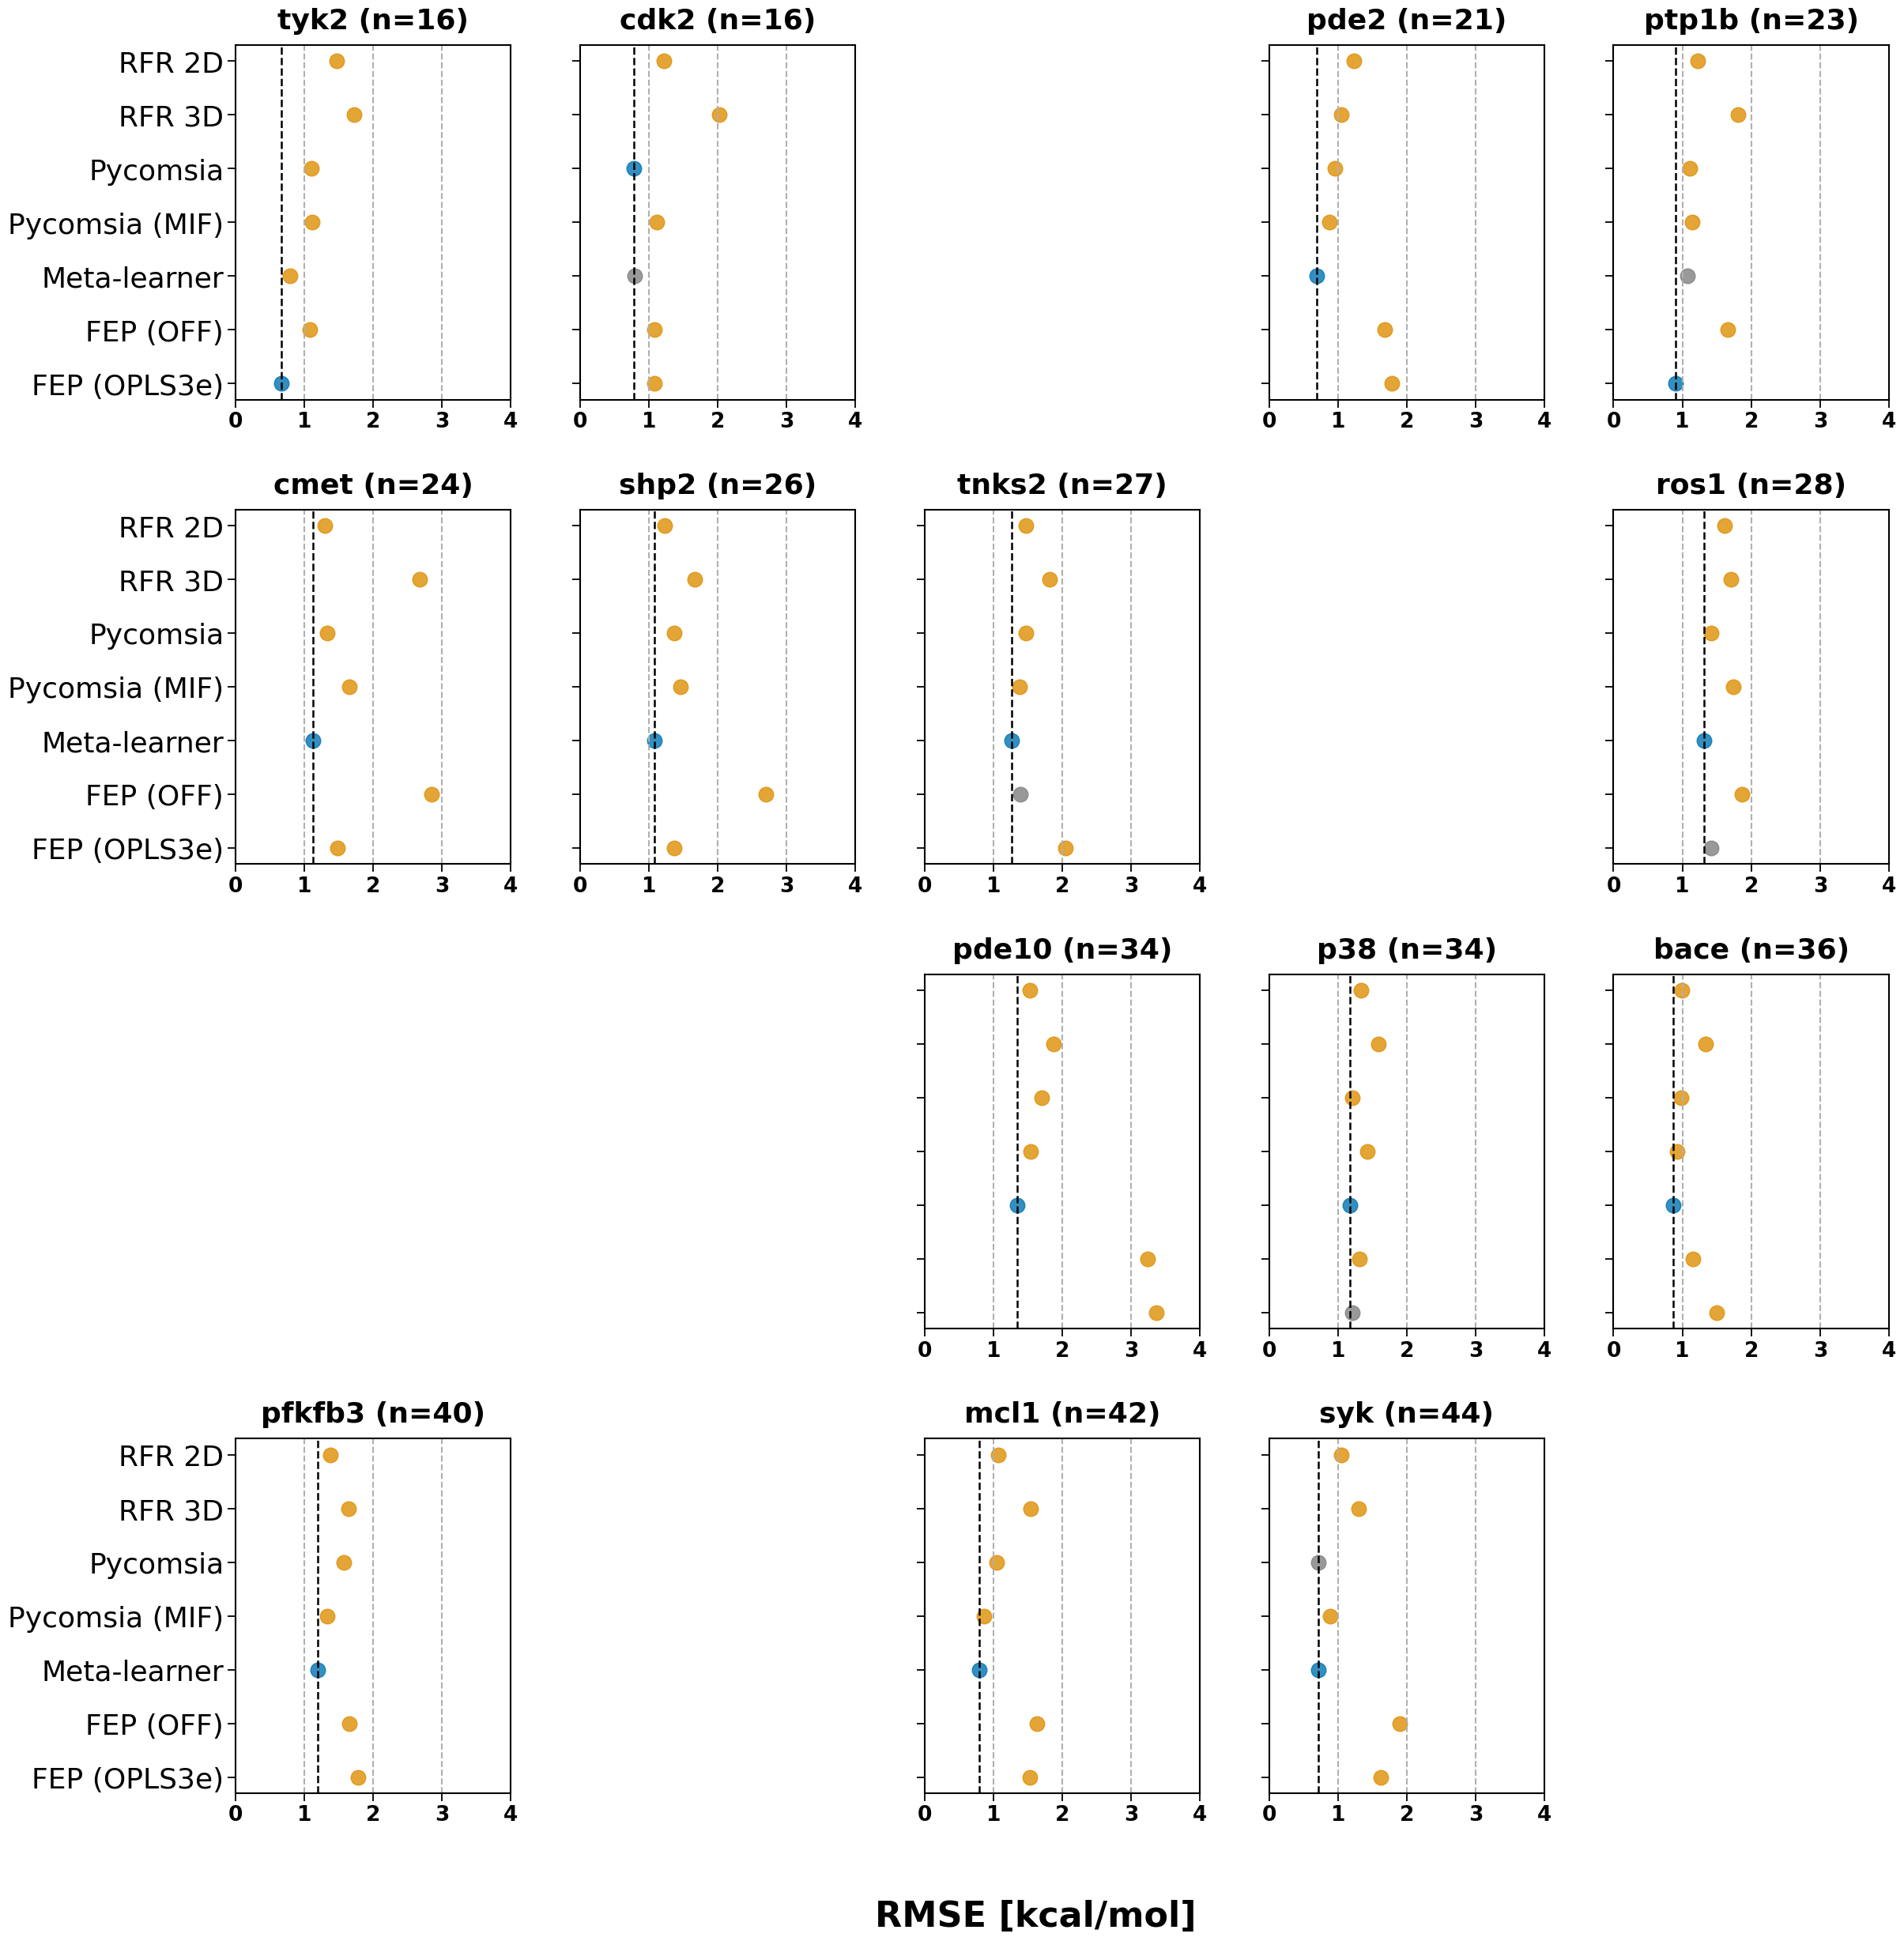

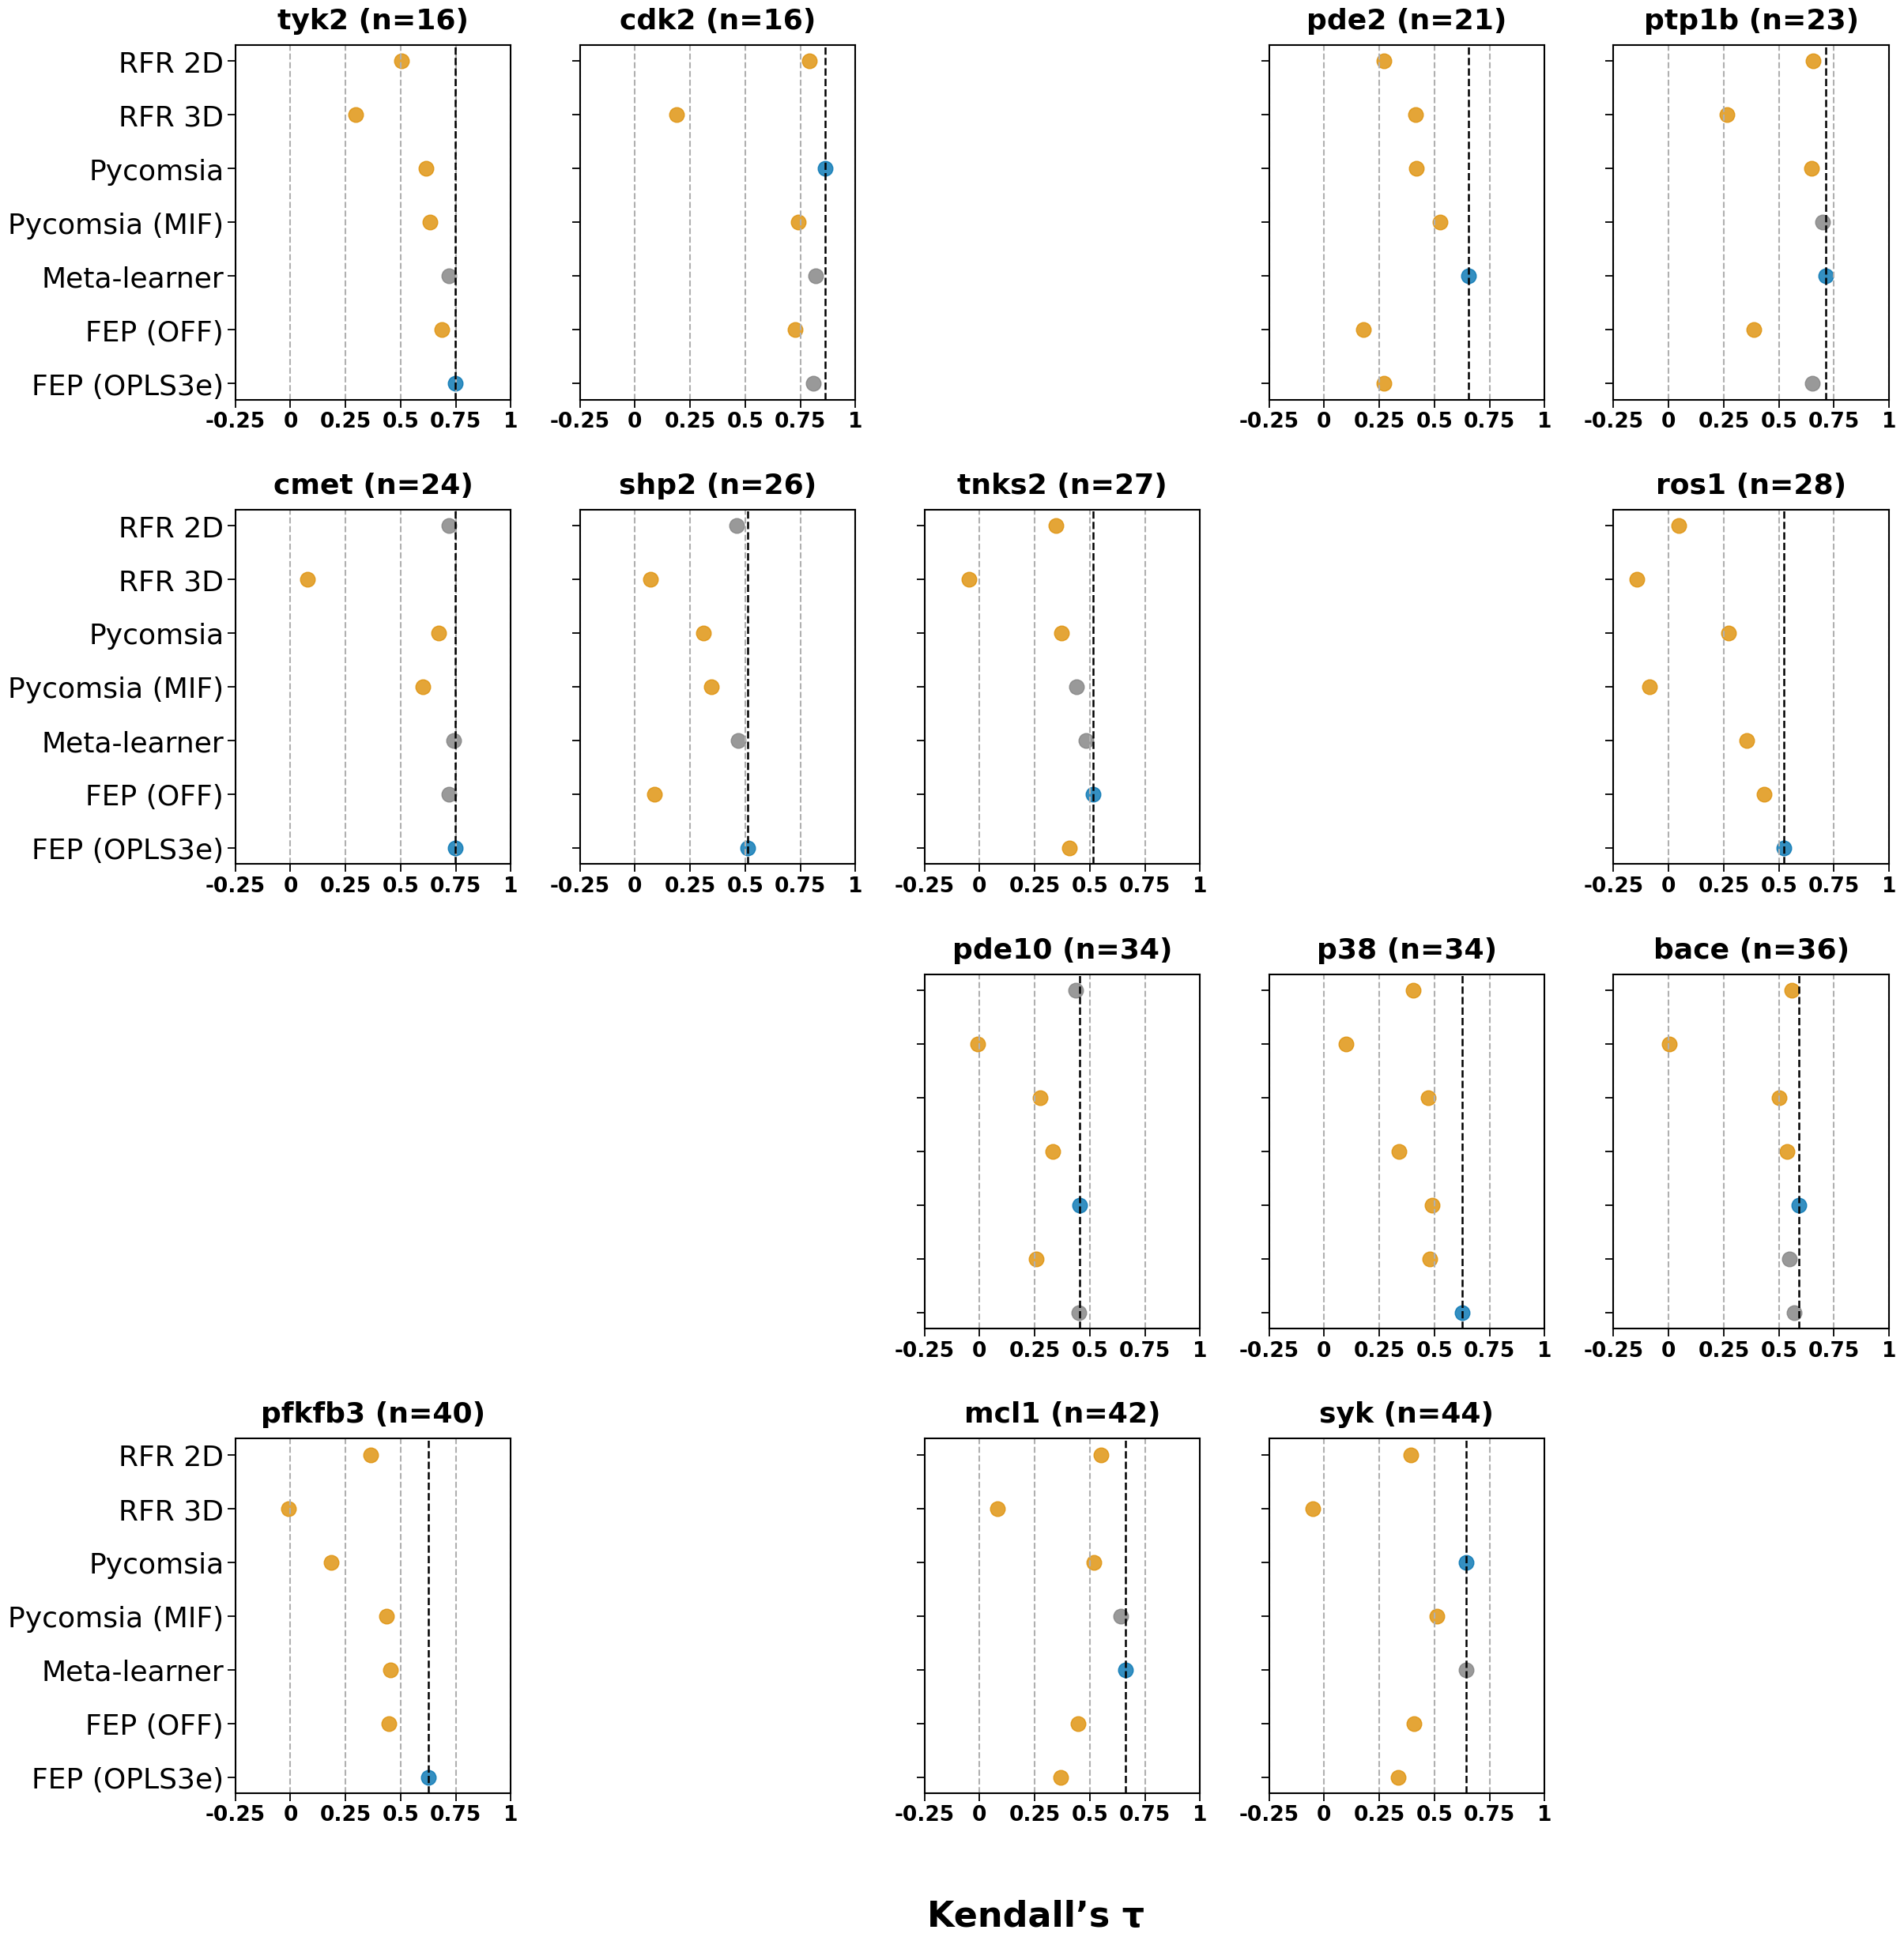

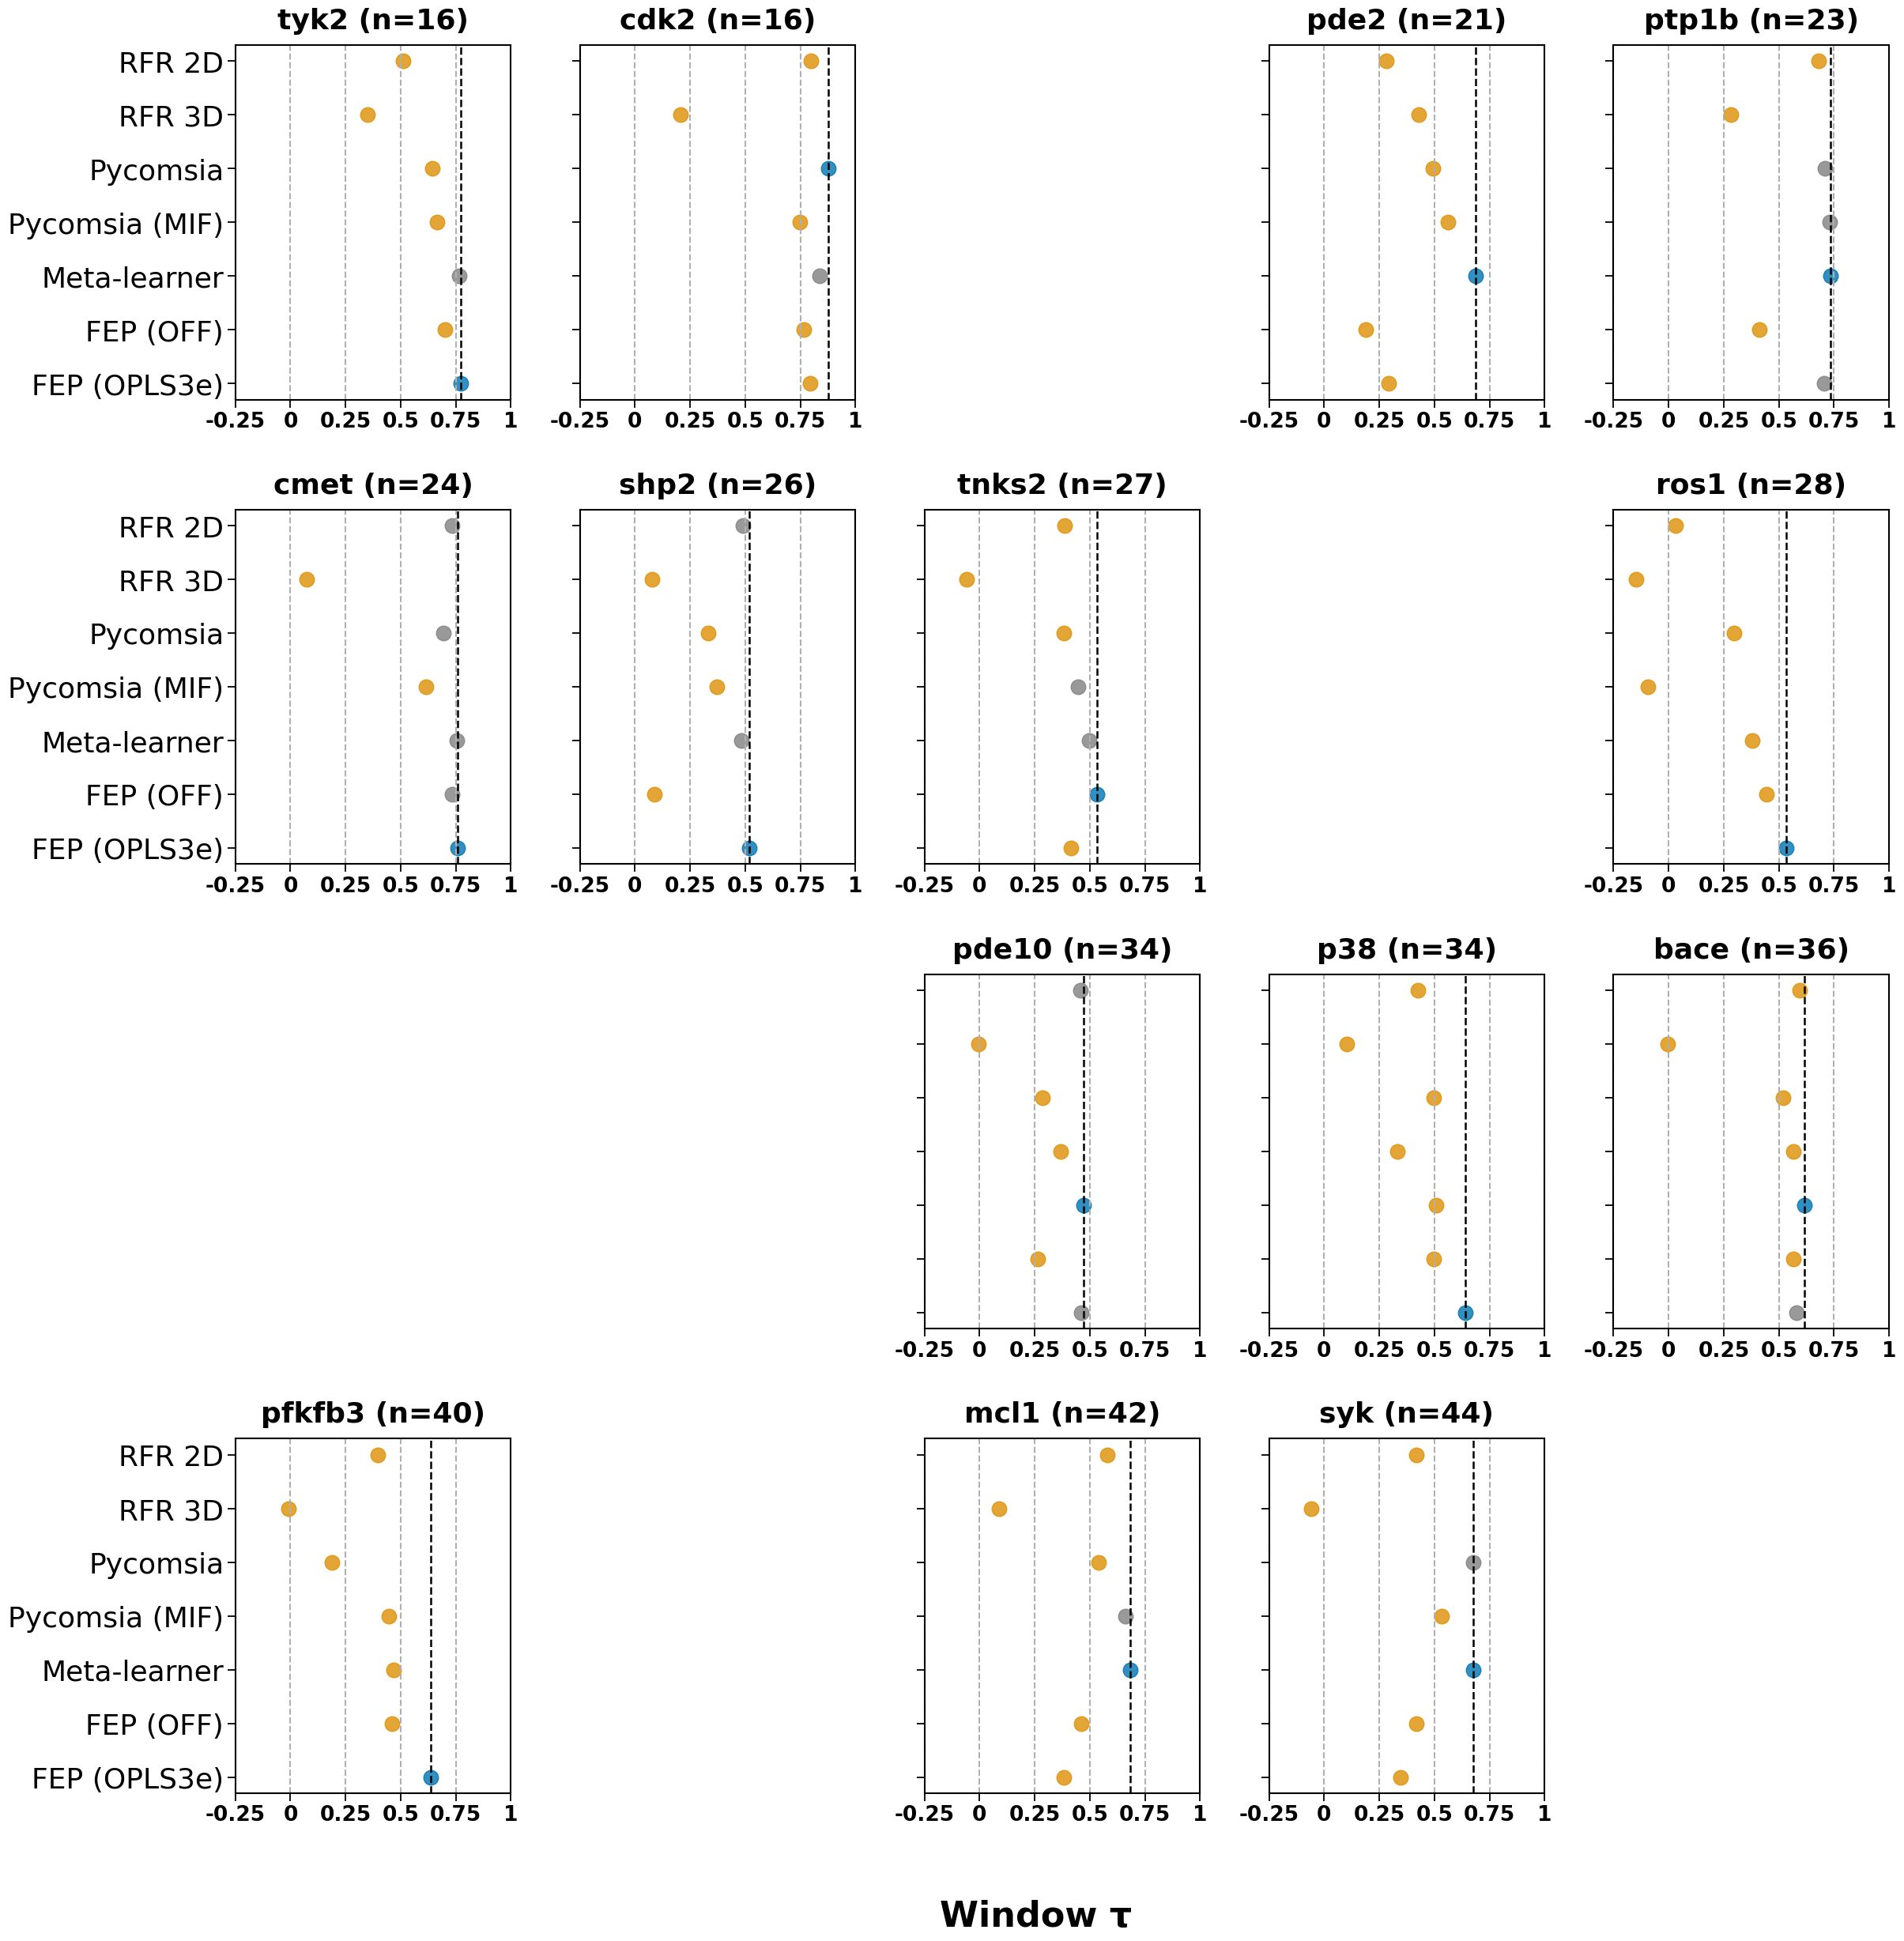

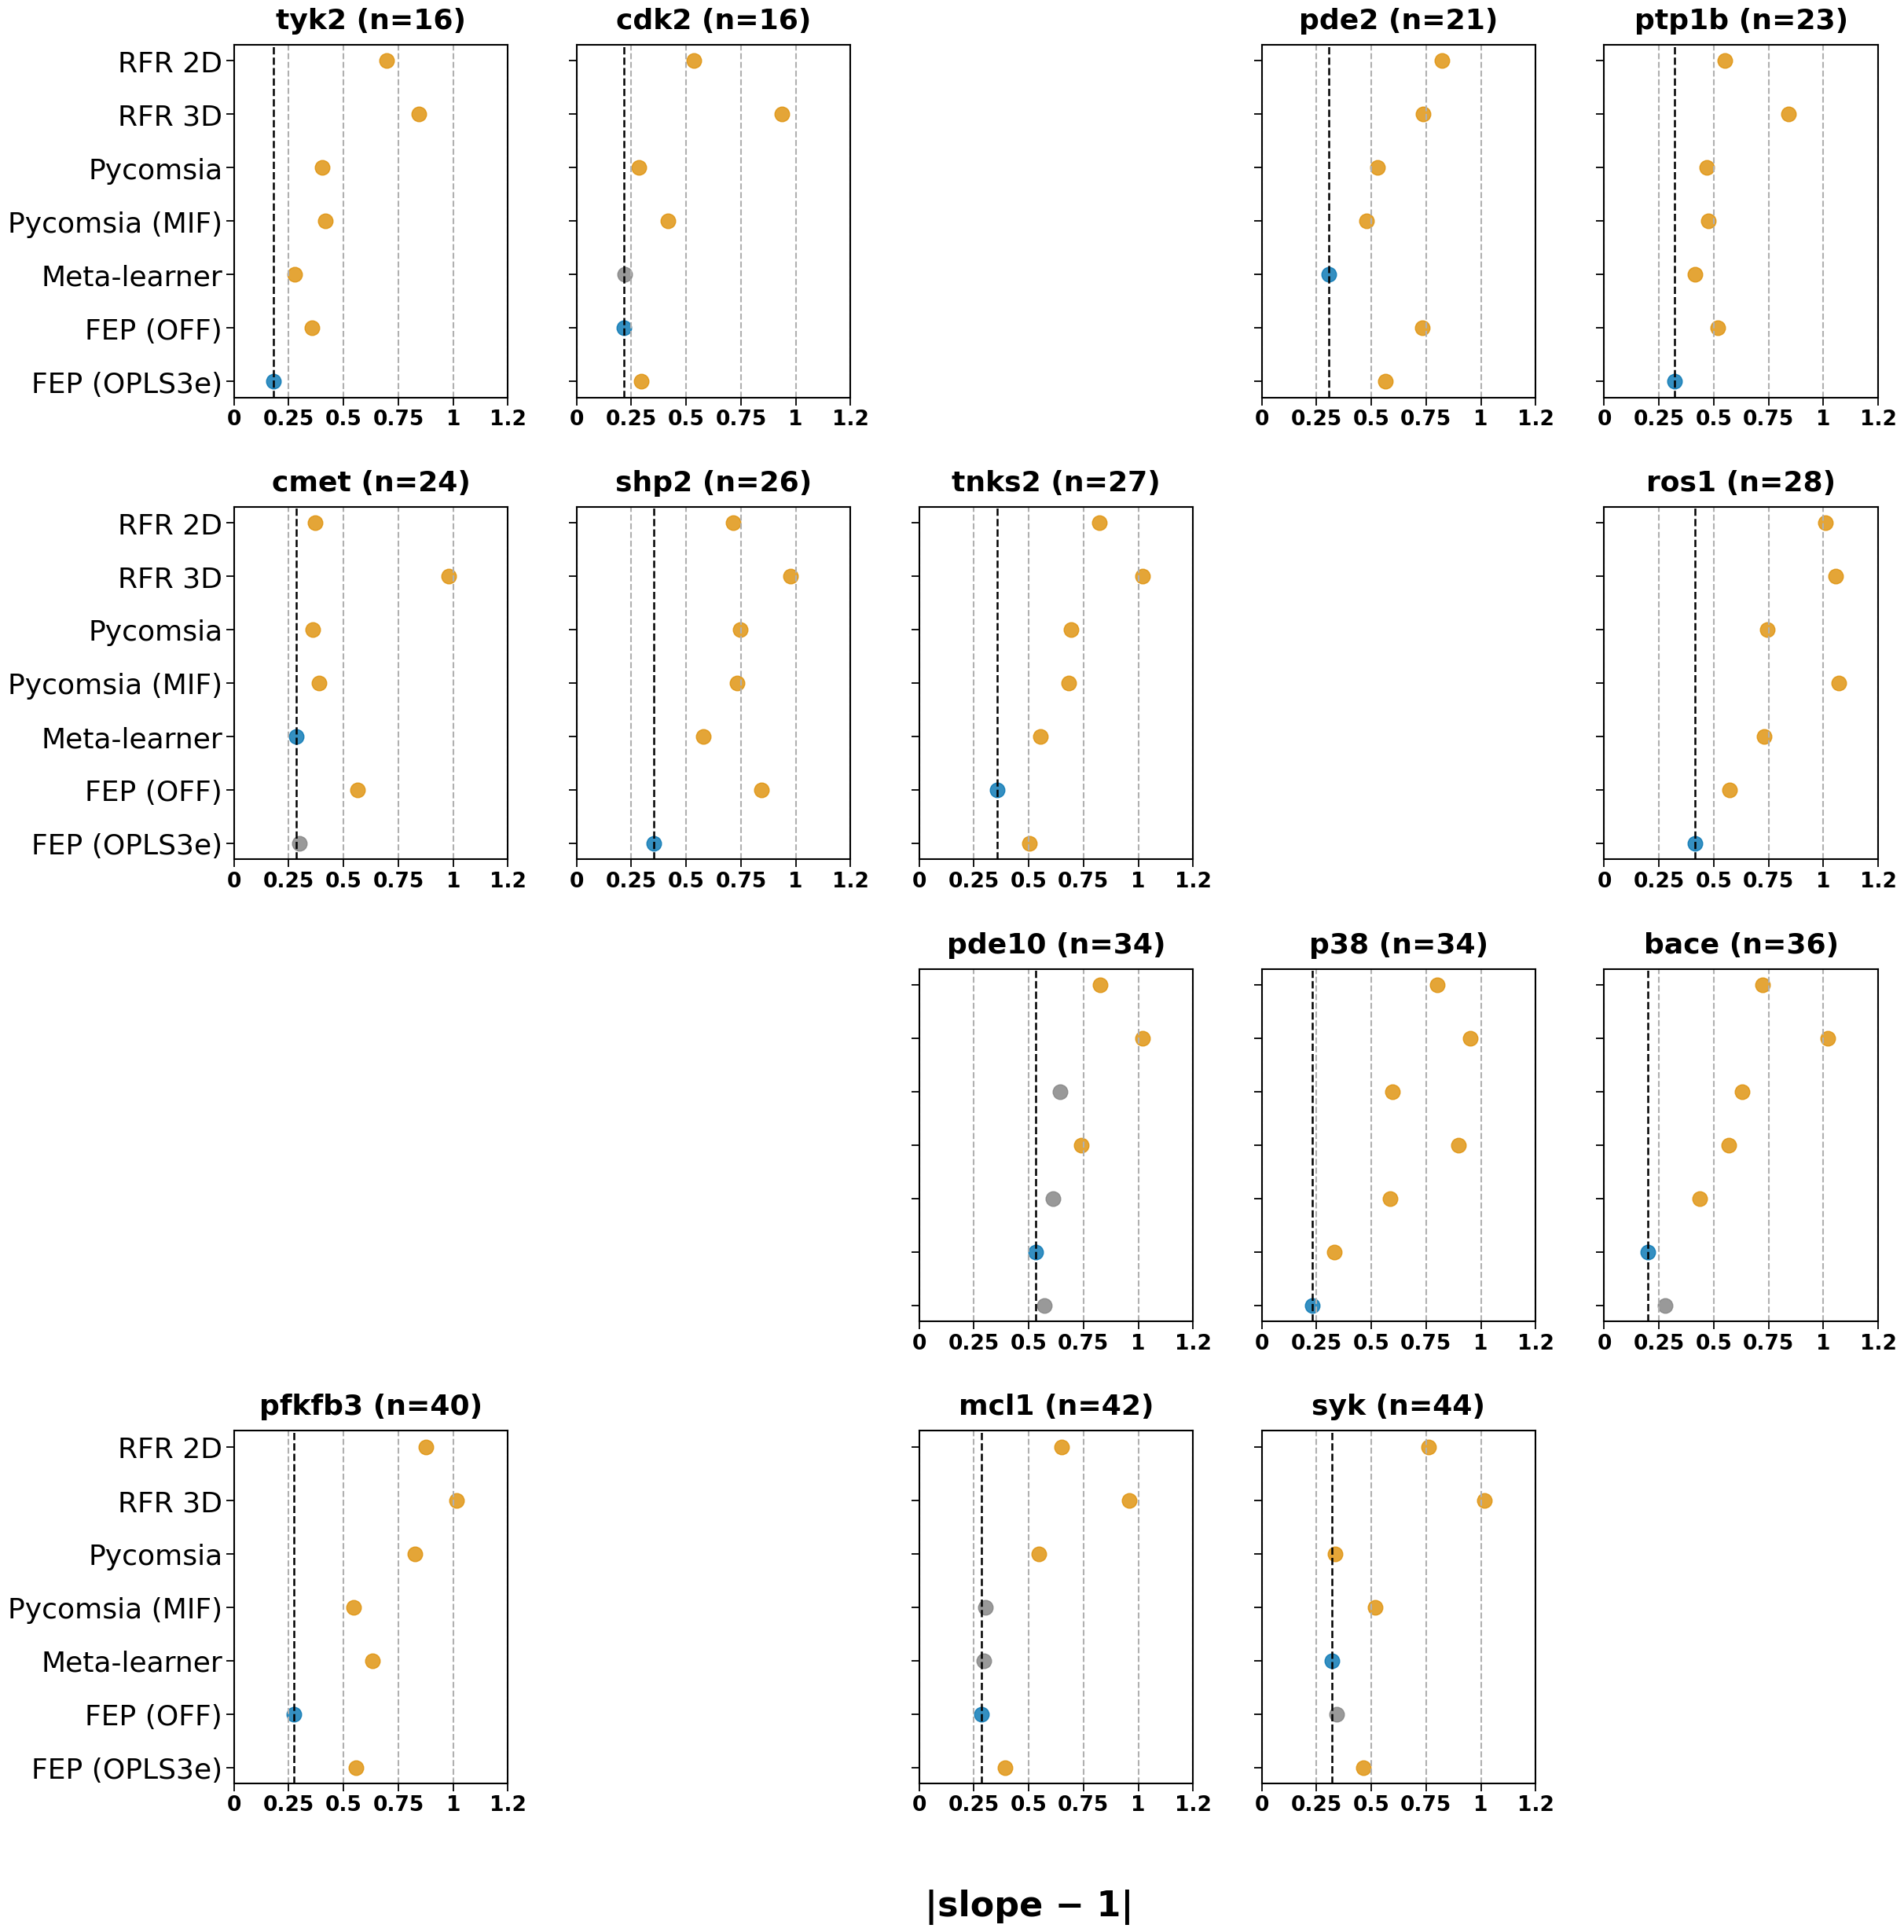

In [7]:
from DDG_ANALYSIS.E_EFFECT_SIZE_PLOT import plot_significance_ranks
plot_significance_ranks(results_all, DISPLAY_ORDER, ALPHA=ALPHA, METRICS=METRICS, target_counts_path="../../../0_DATA/N_COMPOUNDS_PER_TARGET.json", prefix="STRAT_")